# High-accuracy track: all labels + crystal structure + ensemble

The SSL study uses 1,000 labels and the chemical formula only. This notebook shows the best achievable accuracy when every structure of each database is used, with 28 crystal-structure descriptors (symmetry, density, packing, bond lengths, coordination), tuned LightGBM/XGBoost, a stacked ensemble and an accuracy-optimal threshold. The test split is grouped by formula (no composition on both sides).

Full runs: `pipeline/build_structure_dataset.py` then `pipeline/train_high_accuracy.py --task <task>`.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
H = ROOT / "data/predictions/high_accuracy"
from IPython.display import Image, display
tasks = [t for t in ('metallicity', 'magnetism', 'stability', 'band_gap') if (H / f'{t}_summary.json').exists()]
S = {t: json.loads((H / f'{t}_summary.json').read_text()) for t in tasks}
pd.DataFrame({t: S[t]['dataset'] for t in tasks})

,metallicity,magnetism,stability,band_gap
n_structures,104209.000000,87671.000000,499654.00000,104209.000000
n_formulas,78164.000000,64410.000000,436791.00000,78164.000000
positive_rate,0.439233,0.216925,0.27408,0.072758
n_train,83367.000000,70136.000000,399722.00000,83365.000000
n_test,20000.000000,17535.000000,20000.00000,20000.000000
n_features,170.000000,170.000000,170.00000,170.000000
n_structure_features,28.000000,28.000000,28.00000,28.000000


In [2]:
# 1. Structure descriptors of one material (NaCl, conventional and primitive cell)
from pymatgen.core import Lattice, Structure
from structure_features import arrays_from_pymatgen_dict, default_tables, features_from_arrays
T = default_tables()
conv = Structure.from_spacegroup('Fm-3m', Lattice.cubic(5.64), ['Na', 'Cl'], [[0, 0, 0], [0.5, 0.5, 0.5]])
pd.DataFrame({name: features_from_arrays(*arrays_from_pymatgen_dict(st.as_dict(), T['sym2z']), T) for name, st in [('conventional', conv), ('primitive', conv.get_primitive_structure())]}).round(3)

,conventional,primitive
struct_nprim,2.000,2.000
struct_nsym_sites,2.000,2.000
struct_formula_units,1.000,1.000
struct_vpa,22.426,22.426
struct_density,2.164,2.164
struct_packing,0.526,0.526
struct_vol_ratio,0.835,0.835
struct_spg,225.000,225.000
struct_pg_order,48.000,48.000
struct_b_a,1.000,1.000


In [3]:
# 2. Ablation: what each ingredient adds (held-out test structures)
rows = []
for t in tasks:
    for r in S[t]['ablation']:
        rows.append({'task': t, 'step': r['Model'], 'accuracy': r['Accuracy'], 'balanced_accuracy': r['Balanced_Accuracy'], 'F1': r['F1-Score'], 'ROC-AUC': r['ROC-AUC']})
pd.DataFrame(rows).round(4)

,task,step,accuracy,balanced_accuracy,F1,ROC-AUC
0,metallicity,"1. Composition only (LightGBM, all labels)",0.9033,0.8987,0.8866,0.9634
1,metallicity,2. + crystal-structure descriptors,0.9140,0.9097,0.8993,0.9688
2,metallicity,3. + Optuna-tuned LightGBM,0.9130,0.9083,0.8978,0.9680
3,metallicity,4. + stacking (LightGBM + XGBoost + HistGB),0.9151,0.9111,0.9009,0.9694
4,metallicity,"5. + accuracy-optimal threshold (t = 0.49, cho...",0.9150,0.9113,0.9010,0.9694
5,magnetism,"1. Composition only (LightGBM, all labels)",0.9339,0.8947,0.8442,0.9724
6,magnetism,2. + crystal-structure descriptors,0.9449,0.9112,0.8703,0.9821
7,magnetism,3. + Optuna-tuned LightGBM,0.9431,0.9080,0.8658,0.9809
8,magnetism,4. + stacking (LightGBM + XGBoost + HistGB),0.9459,0.9165,0.8739,0.9826
9,magnetism,"5. + accuracy-optimal threshold (t = 0.51, cho...",0.9459,0.9164,0.8740,0.9826


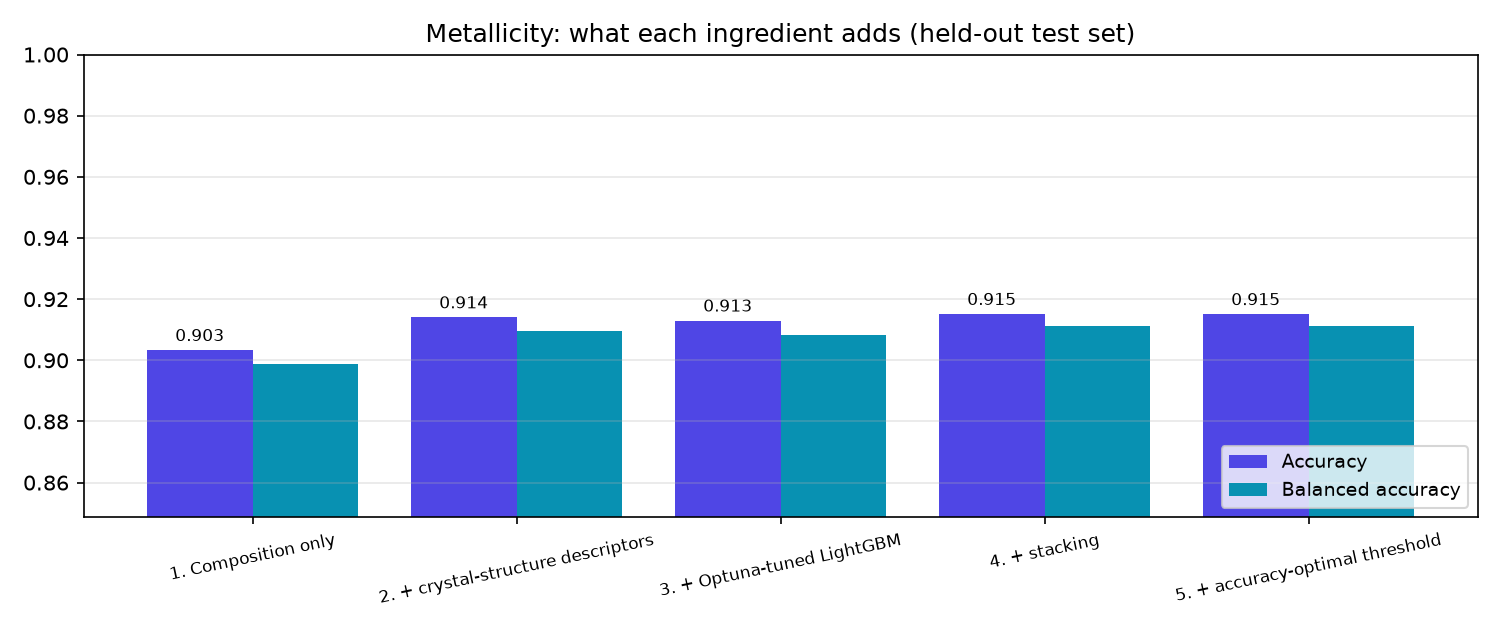

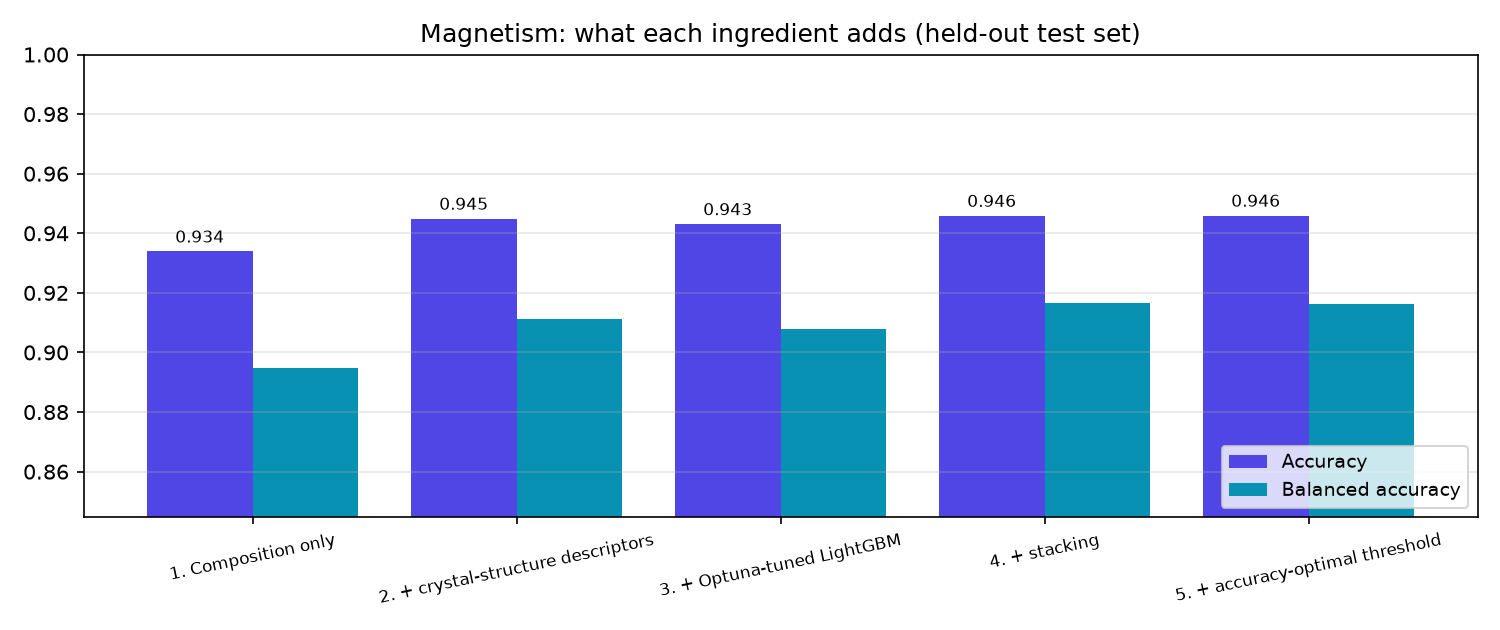

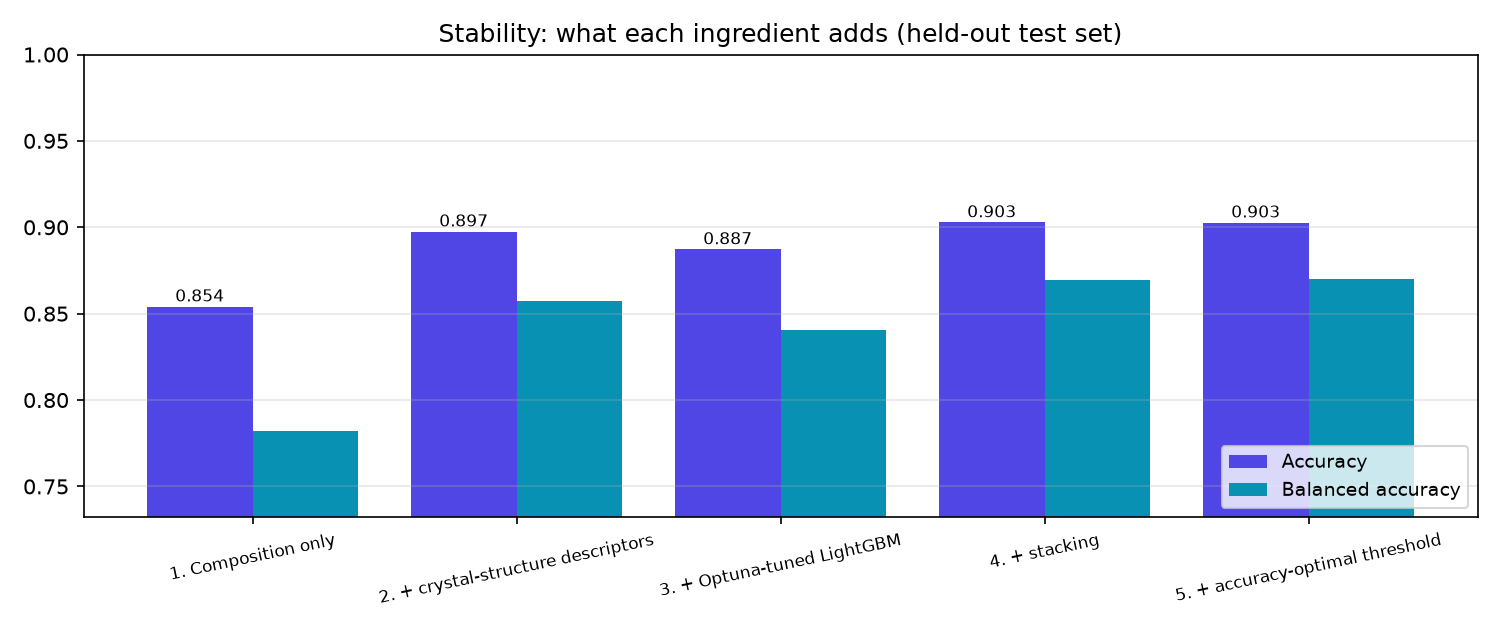

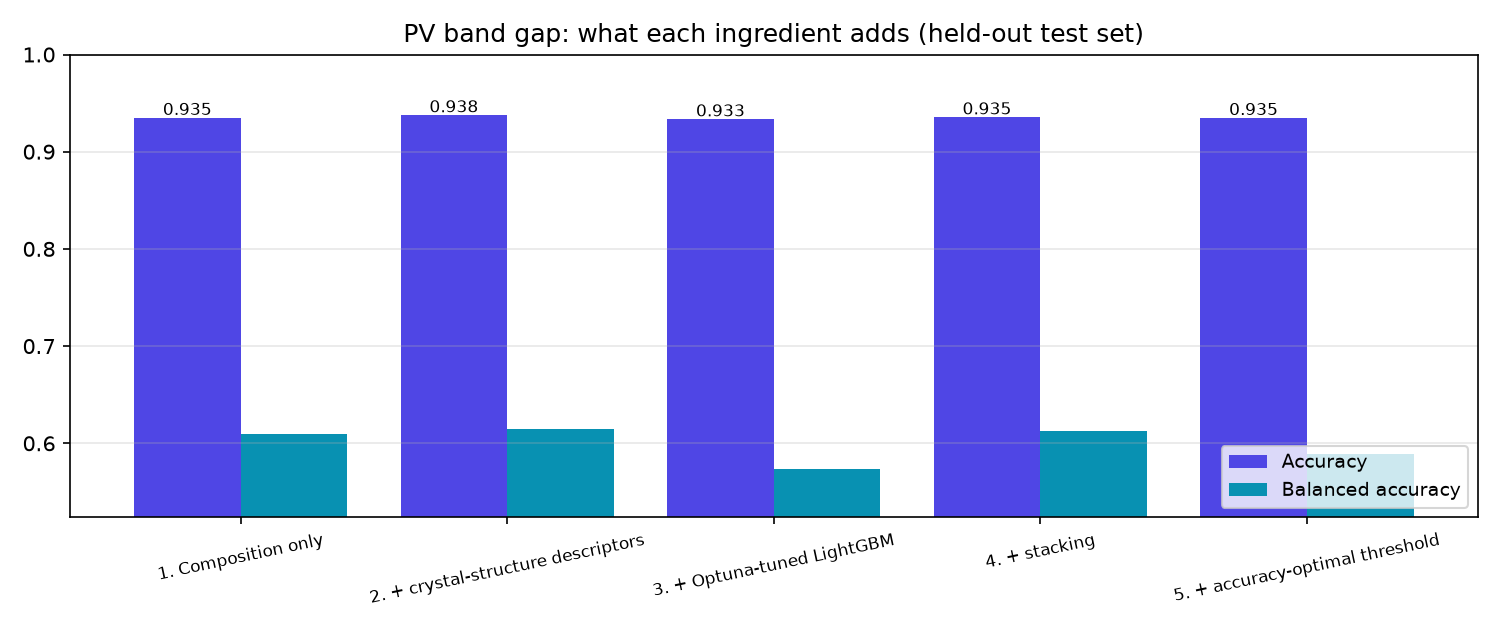

In [4]:
for t in tasks:
    display(Image(str(H / f'{t}_ablation.png')))

In [5]:
# 3. Final models: confusion matrix, threshold and most important descriptors
for t in tasks:
    f = S[t]['final']
    print(f"{t:<12} accuracy={f['Accuracy']:.4f}  balanced={f['Balanced_Accuracy']:.4f}  F1={f['F1-Score']:.4f}  AUC={f['ROC-AUC']:.4f}  threshold={S[t]['threshold']:.2f}")
    print('   confusion [[TN, FP], [FN, TP]] =', S[t]['confusion'])
    print('   top descriptors:', ', '.join(list(S[t]['top_features'])[:6]))

metallicity  accuracy=0.9151  balanced=0.9113  F1=0.9010  AUC=0.9694  threshold=0.49
   confusion [[TN, FP], [FN, TP]] = [[10570, 645], [1054, 7731]]
   top descriptors: MagpieData maximum MendeleevNumber, MagpieData maximum Column, MagpieData maximum NpValence, frac p valence electrons, struct_density, MagpieData mean NpValence
magnetism    accuracy=0.9459  balanced=0.9164  F1=0.8740  AUC=0.9826  threshold=0.51
   confusion [[TN, FP], [FN, TP]] = [[13300, 431], [517, 3287]]
   top descriptors: MagpieData maximum GSmagmom, MagpieData range NdUnfilled, MagpieData range GSmagmom, frac p valence electrons, MagpieData maximum NdUnfilled, MagpieData mean GSmagmom
stability    accuracy=0.9027  balanced=0.8701  F1=0.8181  AUC=0.9612  threshold=0.49
   confusion [[TN, FP], [FN, TP]] = [[13679, 839], [1107, 4375]]
   top descriptors: struct_nprim, struct_nsym_sites, struct_ratio_min, struct_cn_mean, struct_nn_std, struct_vol_ratio
band_gap     accuracy=0.9347  balanced=0.5892  F1=0.2919  AUC=0.

In [6]:
# 4. Use the deployed structure-aware models (offline structure cache)
import os; os.environ['MATSSL_OFFLINE'] = '1'
sys.path.insert(0, str(ROOT))
from app.services import model as service
for f in ['LiFePO4', 'Fe2O3', 'Nd2Fe14B', 'CsPbI3', 'Cu', 'NaCl']:
    r = service.predict(f)
    print(f"{f:<9}", r['structure_status'], {p['task']: (p['prediction_label'], round(p['probability'], 3), p['model_track']) for p in r['predictions']})

LiFePO4   found {'metallicity': ('Non-metal', 0.013, 'structure'), 'magnetism': ('Magnetic', 0.996, 'structure'), 'stability': ('Unstable', 0.468, 'structure'), 'band_gap': ('PBE gap outside 1.1-1.7 eV', 0.05, 'structure')}


Fe2O3     found {'metallicity': ('Non-metal', 0.063, 'structure'), 'magnetism': ('Magnetic', 0.99, 'structure'), 'stability': ('Unstable', 0.275, 'structure'), 'band_gap': ('PBE gap in 1.1-1.7 eV window', 0.779, 'structure')}


Nd2Fe14B  found {'metallicity': ('Metal', 0.995, 'structure'), 'magnetism': ('Magnetic', 0.997, 'structure'), 'stability': ('Stable / near hull', 0.889, 'structure'), 'band_gap': ('PBE gap outside 1.1-1.7 eV', 0.0, 'structure')}


CsPbI3    found {'metallicity': ('Non-metal', 0.022, 'structure'), 'magnetism': ('Non-magnetic', 0.002, 'structure'), 'stability': ('Stable / near hull', 0.808, 'structure'), 'band_gap': ('PBE gap outside 1.1-1.7 eV', 0.249, 'structure')}


Cu        found {'metallicity': ('Metal', 0.994, 'structure'), 'magnetism': ('Non-magnetic', 0.002, 'structure'), 'stability': ('Unstable', 0.088, 'structure'), 'band_gap': ('PBE gap outside 1.1-1.7 eV', 0.0, 'structure')}


NaCl      found {'metallicity': ('Non-metal', 0.01, 'structure'), 'magnetism': ('Non-magnetic', 0.022, 'structure'), 'stability': ('Stable / near hull', 0.792, 'structure'), 'band_gap': ('PBE gap outside 1.1-1.7 eV', 0.006, 'structure')}
